# Conditional GAN (cGAN) pada MNIST
Kode berdasarkan [shinyflight/Simple-GAN-TensorFlow-2.0](https://github.com/shinyflight/Simple-GAN-TensorFlow-2.0/blob/master/cGAN.py), disesuaikan agar berjalan di TensorFlow ≥ 2.16  wef sfaweffawefaefwaefafafafafafafasdadadad

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Hyperparameter & Data

In [2]:
batch_size = 200
epochs = 3000     # kurangi (misal 3000) jika ingin coba cepat
z_dim = 100

# Noise & label tetap untuk visualisasi (digit 0-9)
z_vis = tf.random.normal([10, z_dim])
y_vis = tf.constant(np.eye(10), dtype="float32")

# Load data MNIST
(x_train, y_train), _ = tf.keras.datasets.mnist.load_data()
x_train = (x_train / 255.0).astype("float32")
y_train = tf.one_hot(y_train, depth=10, dtype="float32")
data_iter = iter(tf.data.Dataset.from_tensor_slices((x_train, y_train))
                 .shuffle(4 * batch_size).batch(batch_size).repeat())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## 2. Model
- **Generator**: noise `z` + label `y` → gambar 28×28
- **Discriminator**: gambar + label (diperluas jadi peta 28×28×10) → skor real/fake

In [3]:
def Generator():
    z = layers.Input(shape=(z_dim,))
    y = layers.Input(shape=(10,))
    x = layers.concatenate([z, y])
    x = layers.Dense(3 * 3 * 512)(x)
    x = layers.Reshape((3, 3, 512))(x)

    x = layers.Conv2DTranspose(256, 3, 2, "valid")(x)
    x = layers.LeakyReLU(0.2)(layers.BatchNormalization()(x))

    x = layers.Conv2DTranspose(128, 4, 2, "same")(x)
    x = layers.LeakyReLU(0.2)(layers.BatchNormalization()(x))

    x = layers.Conv2DTranspose(1, 4, 2, "same", activation="sigmoid")(x)
    out = layers.Reshape((28, 28))(x)
    return tf.keras.Model([z, y], out)


def Discriminator():
    X = layers.Input(shape=(28, 28))
    Y = layers.Input(shape=(10,))
    y = layers.RepeatVector(28 * 28)(Y)
    y = layers.Reshape((28, 28, 10))(y)
    x = layers.Reshape((28, 28, 1))(X)
    x = layers.concatenate([x, y])

    x = layers.LeakyReLU(0.2)(layers.Conv2D(128, 4, 2, "same")(x))
    x = layers.LeakyReLU(0.2)(layers.BatchNormalization()(layers.Conv2D(256, 4, 2, "same")(x)))
    x = layers.LeakyReLU(0.2)(layers.BatchNormalization()(layers.Conv2D(512, 4, 2, "same")(x)))
    out = layers.Dense(1)(x)
    return tf.keras.Model([X, Y], out)


G, D = Generator(), Discriminator()
G.summary()
D.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 110)       │          0 │ input_layer[0][0… │
│ (Concatenate)       │                   │            │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4608)      │    511,488 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 3, 3, 512) │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 7, 7, 256) │  1,179,904 │ reshape[0][0]     │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 7, 7, 256) │      1,024 │ conv2d_transpose… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 7, 7, 256) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 14, 14,    │    524,416 │ leaky_re_lu[0][0] │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 14,    │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 14, 14,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 28, 28, 1) │      2,049 │ leaky_re_lu_1[0]… │
│ (Conv2DTranspose)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 28, 28)    │          0 │ conv2d_transpose… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,219,393 (8.47 MB)

 Trainable params: 2,218,625 (8.46 MB)

 Non-trainable params: 768 (3.00 KB)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_2       │ (None, 28, 28)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 784, 10)   │          0 │ input_layer_3[0]… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_3 (Reshape) │ (None, 28, 28, 1) │          0 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 28, 28,    │          0 │ repeat_vector[0]… │
│                     │ 10)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 28, 28,    │          0 │ reshape_3[0][0],  │
│ (Concatenate)       │ 11)               │            │ reshape_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 14, 14,    │     22,656 │ concatenate_1[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 14, 14,    │          0 │ conv2d[0][0]      │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 7, 7, 256) │    524,544 │ leaky_re_lu_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 7, 7, 256) │      1,024 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 7, 7, 256) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 4, 4, 512) │  2,097,664 │ leaky_re_lu_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 4, 4, 512) │      2,048 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_4       │ (None, 4, 4, 512) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4, 4, 1)   │        513 │ leaky_re_lu_4[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,648,449 (10.10 MB)

 Trainable params: 2,646,913 (10.10 MB)

 Non-trainable params: 1,536 (6.00 KB)

## 3. Loss, Optimizer, dan Langkah Training

In [4]:
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)
G_opt = tf.keras.optimizers.Adam(2e-4)
D_opt = tf.keras.optimizers.Adam(2e-4)

@tf.function
def train_step(x_real, y):
    z = tf.random.normal([tf.shape(x_real)[0], z_dim])
    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
        x_fake = G([z, y], training=True)
        d_real = D([x_real, y], training=True)
        d_fake = D([x_fake, y], training=True)
        g_loss = bce(tf.ones_like(d_fake), d_fake)
        d_loss = bce(tf.ones_like(d_real), d_real) + bce(tf.zeros_like(d_fake), d_fake)
    G_opt.apply_gradients(zip(g_tape.gradient(g_loss, G.trainable_variables), G.trainable_variables))
    D_opt.apply_gradients(zip(d_tape.gradient(d_loss, D.trainable_variables), D.trainable_variables))
    return g_loss, d_loss

## 4. Training
Gambar digit 0–9 ditampilkan setiap 100 iterasi.

epoch: 1; G_loss: 0.664177; D_loss: 1.685781


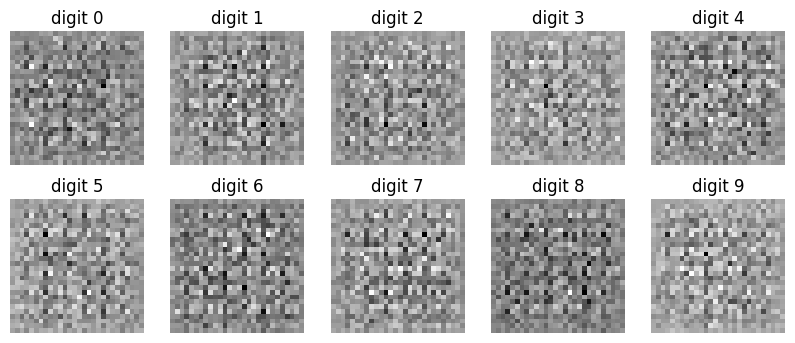

epoch: 101; G_loss: 1.136575; D_loss: 0.937861


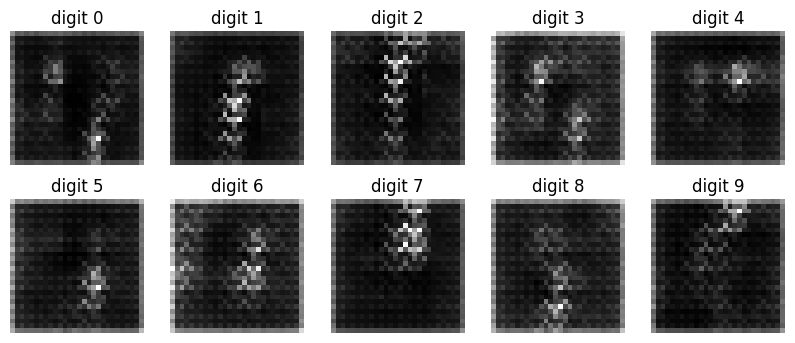

epoch: 201; G_loss: 0.860451; D_loss: 1.085884


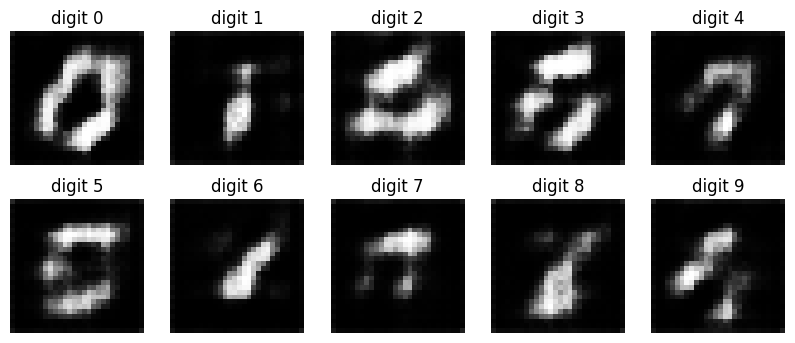

epoch: 301; G_loss: 0.817842; D_loss: 1.173903


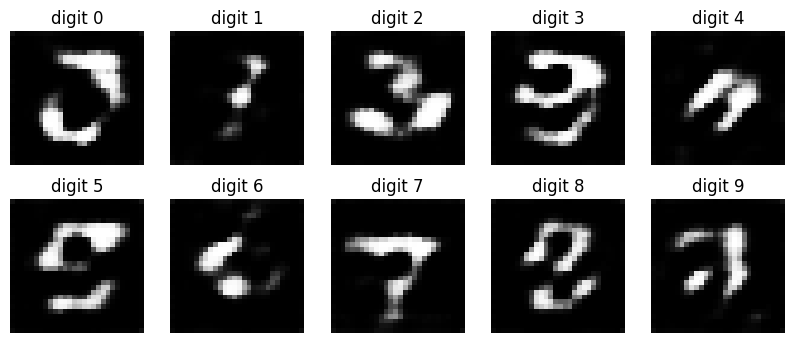

epoch: 401; G_loss: 0.904607; D_loss: 1.043034


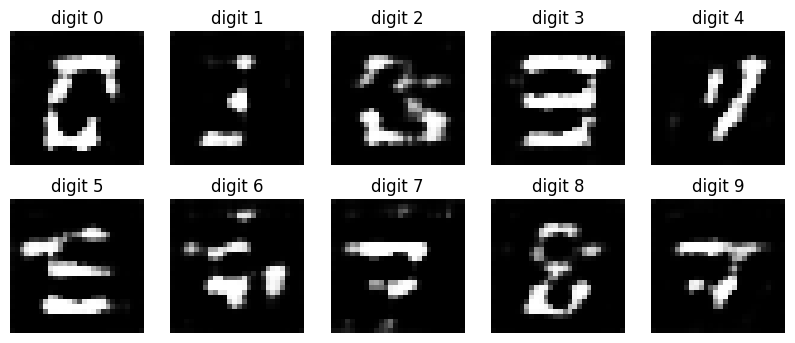

epoch: 501; G_loss: 0.864025; D_loss: 1.132257


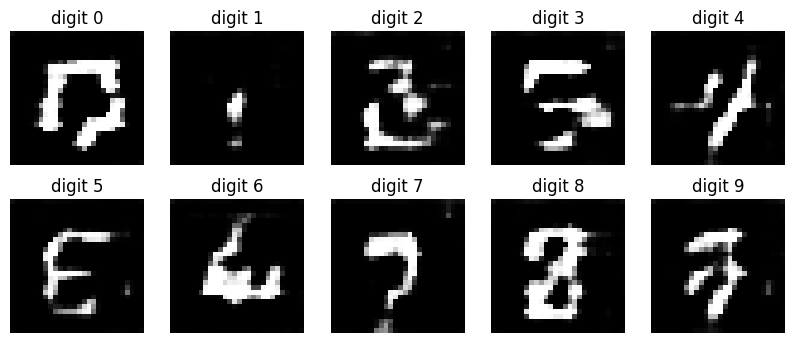

epoch: 601; G_loss: 0.939510; D_loss: 1.118133


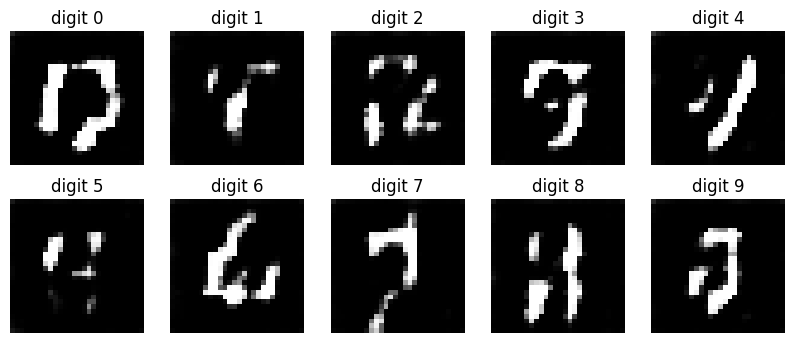

epoch: 701; G_loss: 0.808547; D_loss: 1.250657


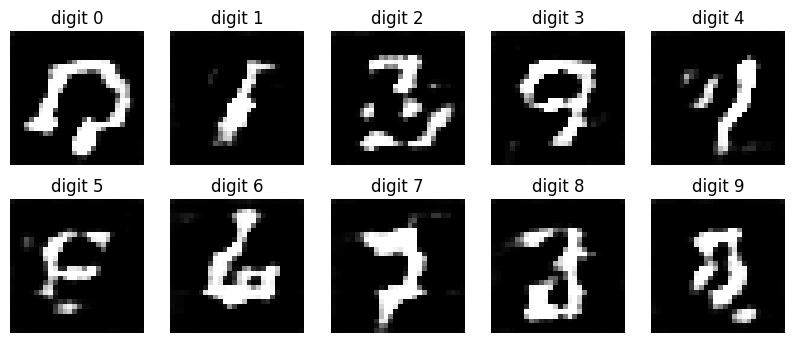

epoch: 801; G_loss: 1.050095; D_loss: 0.969764


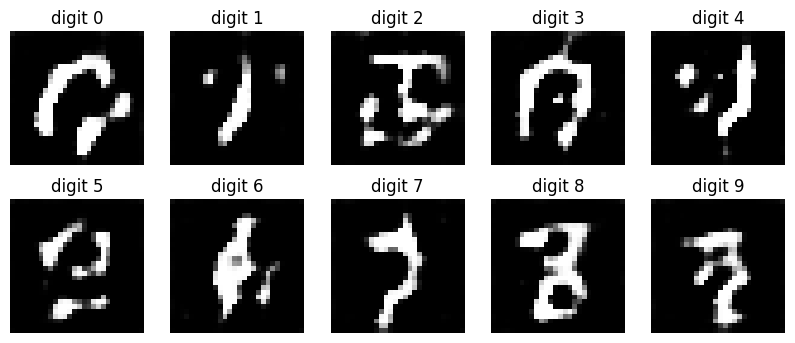

epoch: 901; G_loss: 0.911325; D_loss: 1.029418


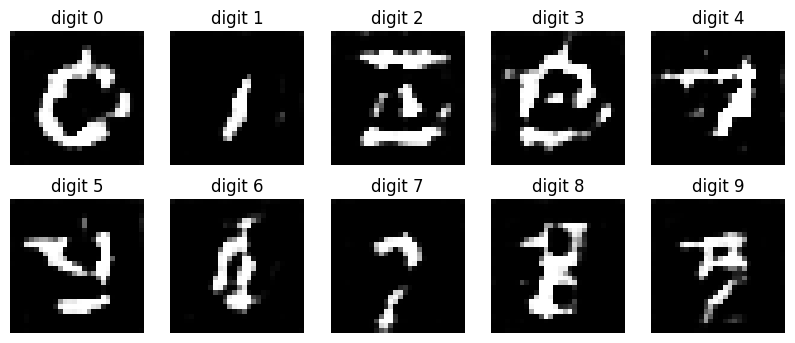

epoch: 1001; G_loss: 1.080845; D_loss: 0.982478


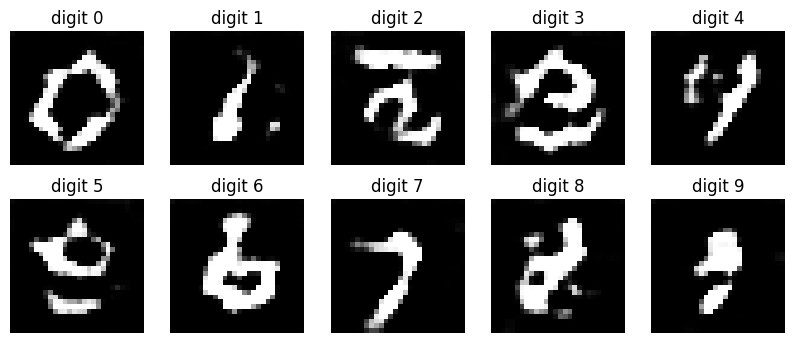

epoch: 1101; G_loss: 0.965046; D_loss: 1.026686


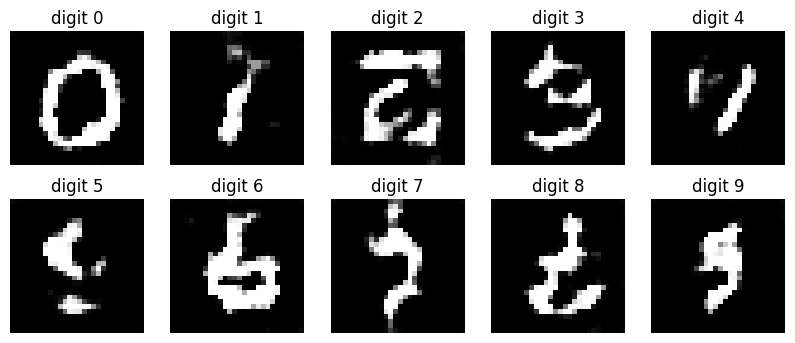

epoch: 1201; G_loss: 1.056561; D_loss: 1.015258


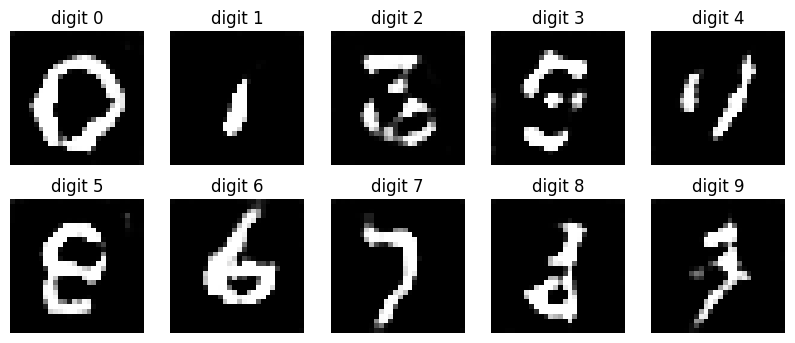

epoch: 1301; G_loss: 1.187891; D_loss: 0.879813


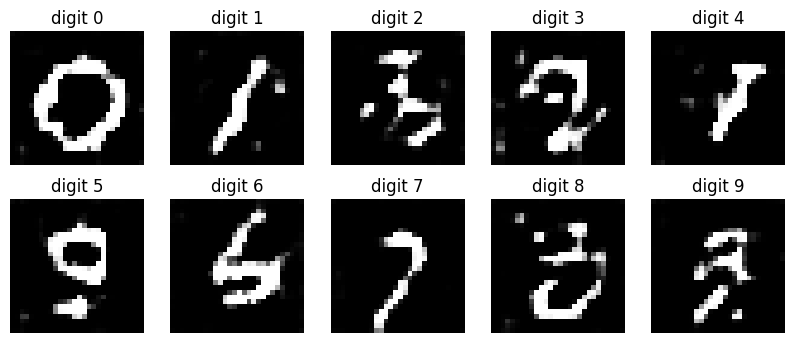

epoch: 1401; G_loss: 1.093650; D_loss: 0.979714


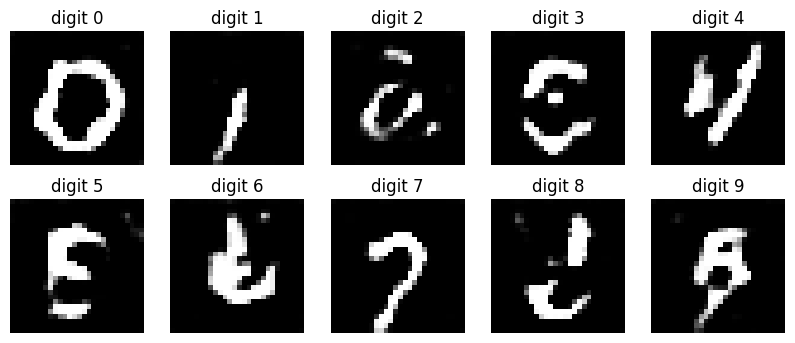

epoch: 1501; G_loss: 1.257939; D_loss: 0.790757


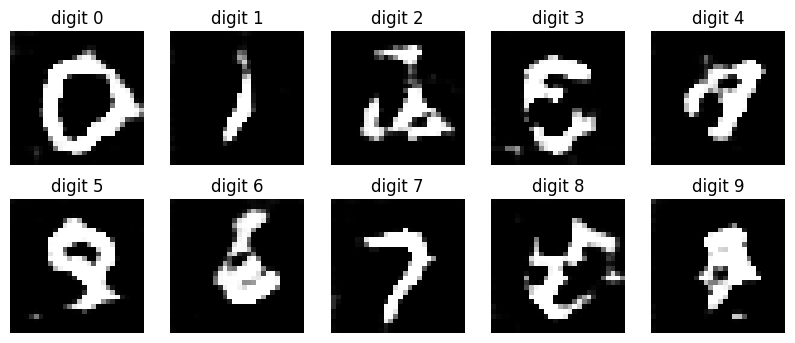

epoch: 1601; G_loss: 1.209003; D_loss: 0.871294


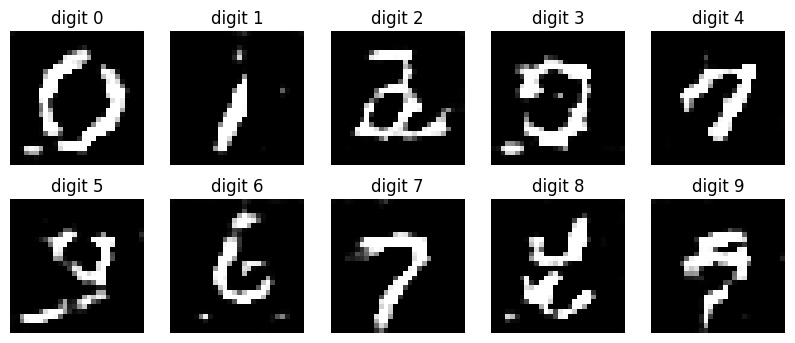

epoch: 1701; G_loss: 1.109596; D_loss: 0.856173


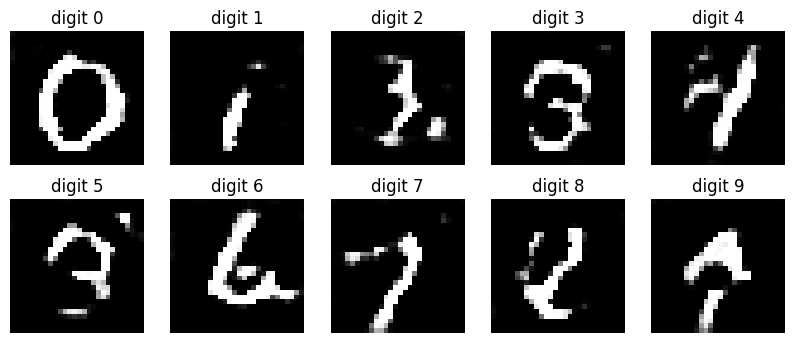

epoch: 1801; G_loss: 1.278479; D_loss: 0.860439


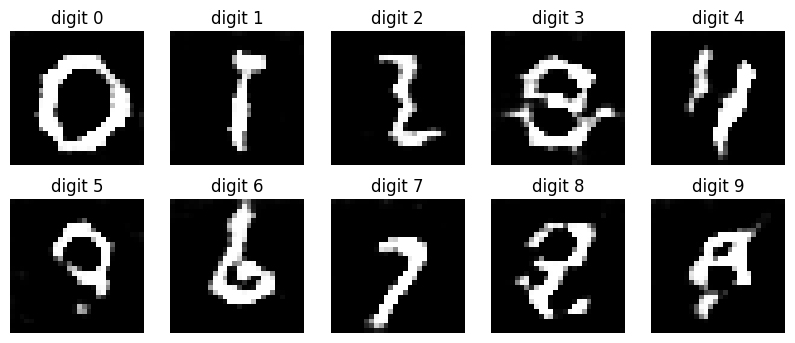

epoch: 1901; G_loss: 1.112729; D_loss: 0.856972


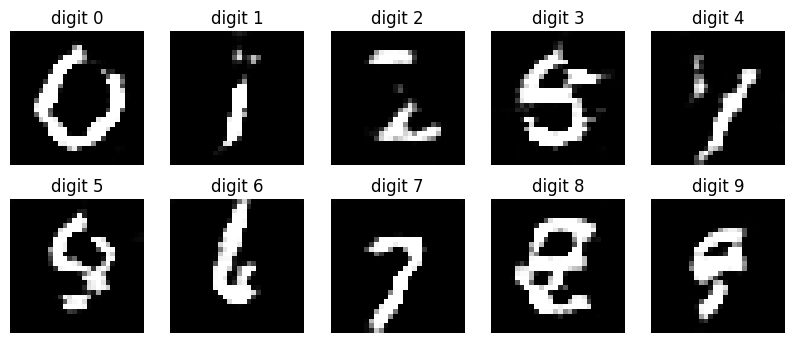

epoch: 2001; G_loss: 1.312546; D_loss: 0.748124


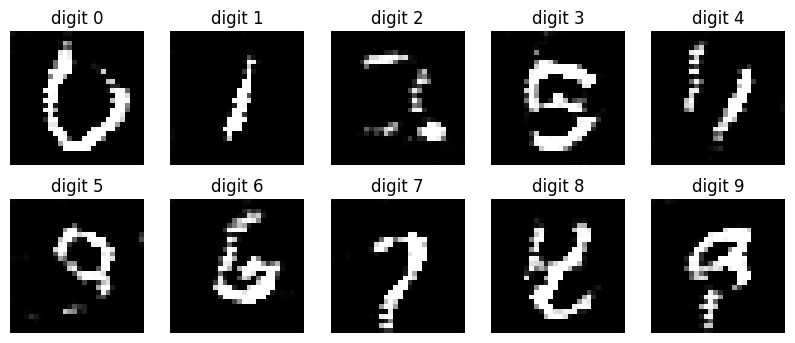

epoch: 2101; G_loss: 1.371546; D_loss: 0.643736


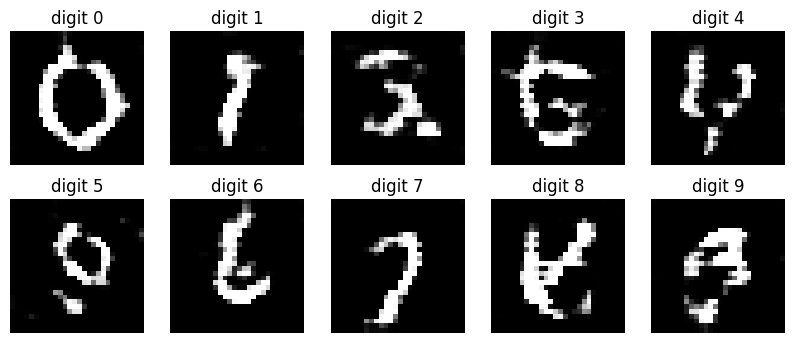

epoch: 2201; G_loss: 1.608670; D_loss: 0.574598


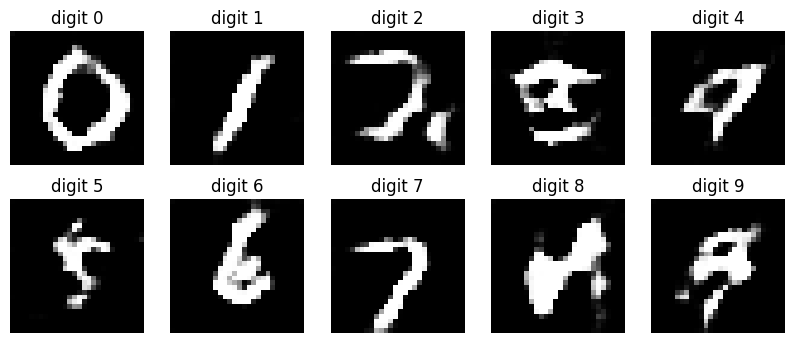

epoch: 2301; G_loss: 1.269067; D_loss: 0.788583


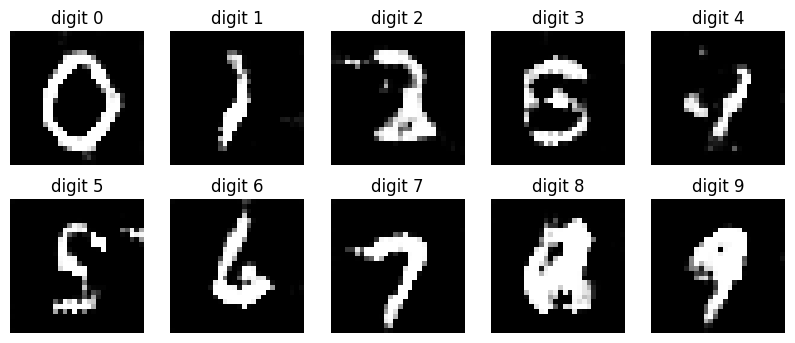

epoch: 2401; G_loss: 1.071502; D_loss: 0.925157


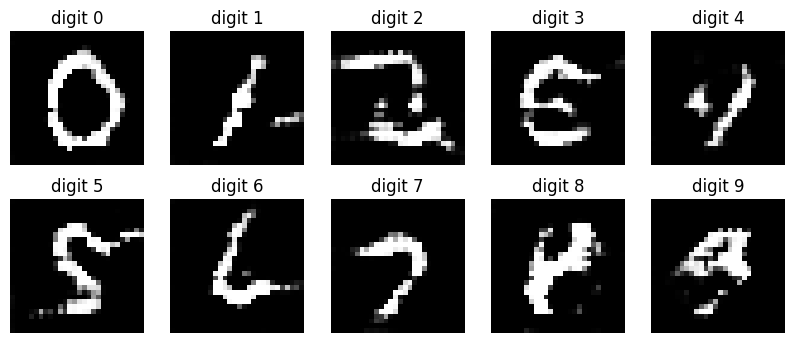

epoch: 2501; G_loss: 1.219592; D_loss: 0.742637


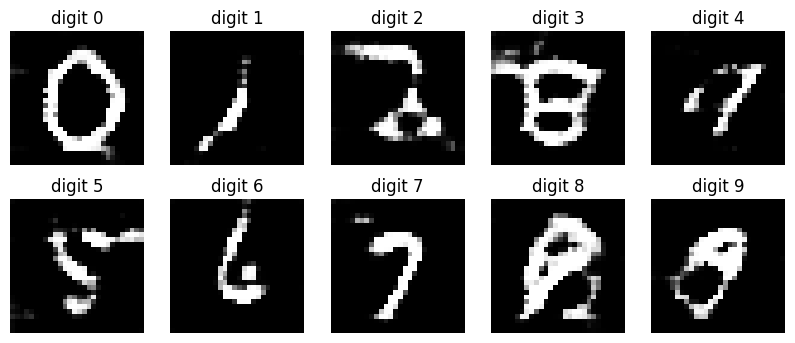

epoch: 2601; G_loss: 1.350630; D_loss: 0.744060


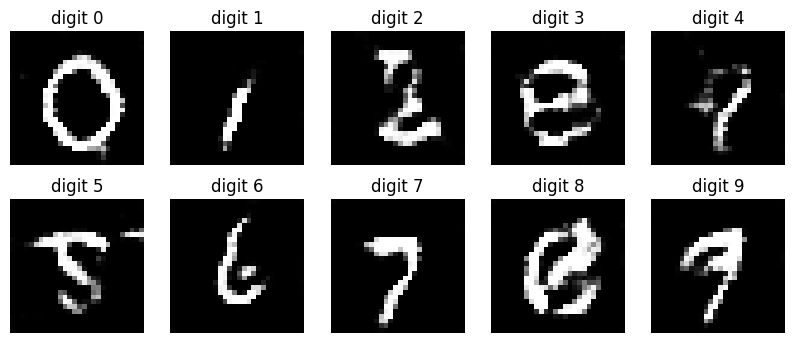

epoch: 2701; G_loss: 1.542664; D_loss: 0.564654


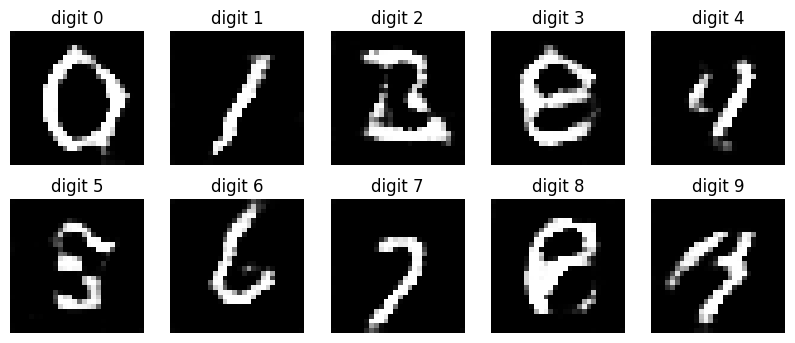

epoch: 2801; G_loss: 1.119650; D_loss: 0.940266


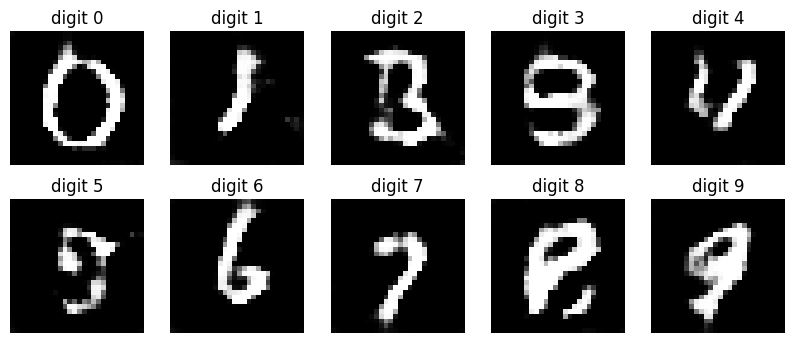

epoch: 2901; G_loss: 1.689381; D_loss: 0.741835


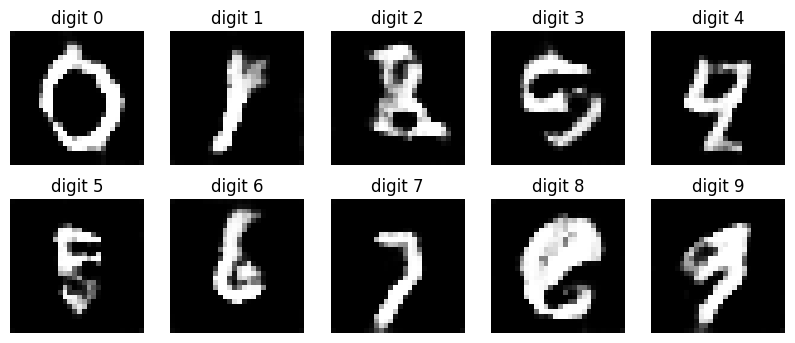

In [5]:
g_hist, d_hist = [], []

for epoch in range(epochs):
    x_real, y = next(data_iter)
    g_loss, d_loss = train_step(x_real, y)
    g_hist.append(float(g_loss)); d_hist.append(float(d_loss))

    if epoch % 100 == 0:
        print(f"epoch: {epoch+1}; G_loss: {float(g_loss):.6f}; D_loss: {float(d_loss):.6f}")
        imgs = G([z_vis, y_vis], training=False).numpy()
        plt.figure(figsize=(10, 4))
        for i in range(10):
            plt.subplot(2, 5, i + 1)
            plt.imshow(imgs[i] * 255.0, cmap="gray")
            plt.title(f"digit {i}"); plt.axis("off")
        plt.show()

## 5. Kurva Loss

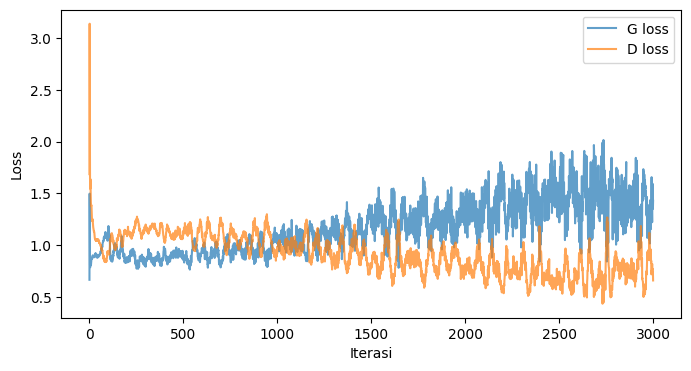

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(g_hist, label="G loss", alpha=0.7)
plt.plot(d_hist, label="D loss", alpha=0.7)
plt.xlabel("Iterasi"); plt.ylabel("Loss"); plt.legend(); plt.show()

## 6. Analisis Perbedaan Metode GAN

| Aspek | GAN (vanilla) | cGAN | DCGAN | WGAN / WGAN-GP |
|---|---|---|---|---|
| Ide utama | G dan D bermain *minimax* | GAN + **label/kondisi** pada input G dan D | GAN dengan arsitektur **konvolusi** | Loss diganti **jarak Wasserstein** |
| Input generator | Noise `z` | Noise `z` + label `y` | Noise `z` | Noise `z` |
| Kontrol hasil | Tidak bisa (acak) | **Bisa** (pilih kelas) | Tidak bisa | Tidak bisa |
| Arsitektur | MLP | MLP atau CNN | CNN + BatchNorm | Bebas (biasanya CNN) |
| Loss D | Binary cross-entropy | Binary cross-entropy (bersyarat) | Binary cross-entropy | Skor kritik, tanpa sigmoid |
| Stabilitas | Sulit, rawan *mode collapse* | Mirip GAN | Lebih stabil | **Paling stabil** |
| Kelemahan | Tidak stabil | Butuh data berlabel | Masih bisa mode collapse | Lebih lambat, perlu gradient penalty |

**Catatan:**
1. GAN vanilla hanya menghasilkan sampel acak dari distribusi data.
2. cGAN menambahkan label `y` ke generator dan diskriminator, sehingga D menilai apakah gambar *real dan sesuai labelnya*, dan G dapat diminta menghasilkan digit tertentu.
3. Kode ini adalah **cGAN dengan arsitektur bergaya DCGAN** (Conv2DTranspose, Conv2D stride 2, BatchNorm, LeakyReLU).
4. WGAN mengatasi vanishing gradient dan mode collapse; nilai loss-nya berkorelasi dengan kualitas gambar.
5. Metode lain: CycleGAN, Pix2Pix, StyleGAN, LSGAN.
